# 06 · Fire weather vs climate

**Question:** why did the fire get out of control? We test it with data:

- **Fuel story:** a wet winter grows lots of grass, then a dry summer turns it into fuel.
- **Ignition days:** heat, very low humidity, wind.

**Data:** ERA5 reanalysis (a reconstruction of past weather) through the free **Open-Meteo** API, for one point at the centre of the AOI, so it is a general picture and not the weather at each fire front. We compare 2025–26 with the **1991–2020 climate normal** (the 30-year average).

An **API** is a web address that returns data instead of a web page. We send the place, the dates and the variables we want, and get a table back.

In [1]:
import pandas as pd
import requests
import matplotlib.pyplot as plt
from common import *

OPEN_METEO = "https://archive-api.open-meteo.com/v1/archive"
lat = (CFG["bbox"][1] + CFG["bbox"][3]) / 2
lon = (CFG["bbox"][0] + CFG["bbox"][2]) / 2
fire = pd.Timestamp(CFG["fire_start"])
print(f"Point: {lat:.3f} N, {lon:.3f} E   ignition {fire.date()}")

Point: 40.380 N, -4.500 E   ignition 2026-07-22


In [2]:
def om(start, end, daily):
    r = requests.get(OPEN_METEO, timeout=120, params={
        "latitude": lat, "longitude": lon, "start_date": start, "end_date": end,
        "daily": ",".join(daily), "timezone": "Europe/Madrid"})
    r.raise_for_status()                      # stop with an error if the request failed
    df = pd.DataFrame(r.json()["daily"])
    df["time"] = pd.to_datetime(df["time"])
    return df.set_index("time")


obs = om(f"{fire.year - 1}-10-01", (fire + pd.Timedelta(days=14)).date().isoformat(),
         ["temperature_2m_max", "relative_humidity_2m_min", "wind_gusts_10m_max", "precipitation_sum"])
clim = om("1991-01-01", "2020-12-31", ["temperature_2m_max", "precipitation_sum"])
obs.tail()

,temperature_2m_max,relative_humidity_2m_min,wind_gusts_10m_max,precipitation_sum
time,,,,
2026-08-01,33.7,15,61.6,0.0
2026-08-02,31.2,21,40.7,0.0
2026-08-03,28.4,27,47.5,0.0
2026-08-04,29.6,34,29.2,0.0
2026-08-05,31.6,27,36.7,0.0


## 1. Compare with "normal"
- **Temperature:** the average max temperature for each day of the year, over 1991–2020.
- **Rain:** monthly totals vs the average for that month.

In [3]:
obs["tmax_normal"] = clim["temperature_2m_max"].groupby(clim.index.day_of_year).mean() \
    .reindex(obs.index.day_of_year).values
pm = obs["precipitation_sum"].resample("MS").sum()
pc = clim["precipitation_sum"].resample("MS").sum()
pc = pc.groupby(pc.index.month).mean()
rain = pd.DataFrame({"obs_mm": pm, "normal_mm": pc.reindex(pm.index.month).values})
rain["pct_of_normal"] = (100 * rain["obs_mm"] / rain["normal_mm"]).round(0)
rain.to_csv(OUT / "step6_rain_vs_normal.csv")
rain

,obs_mm,normal_mm,pct_of_normal
time,,,
2025-10-01,49.4,70.643333,70.0
2025-11-01,134.4,66.366667,203.0
2025-12-01,74.4,55.556667,134.0
2026-01-01,143.0,48.170000,297.0
2026-02-01,141.0,40.516667,348.0
2026-03-01,49.1,52.246667,94.0
2026-04-01,62.8,57.043333,110.0
2026-05-01,69.1,55.610000,124.0
2026-06-01,6.0,25.143333,24.0


In [4]:
wk = obs.loc[fire - pd.Timedelta(days=3): fire + pd.Timedelta(days=4)]
hot = obs[(obs.index >= fire - pd.Timedelta(days=45)) & (obs.index <= fire)]
res = {"point": [round(lat, 3), round(lon, 3)],
       "ignition_week": {"tmax_max_C": round(float(wk["temperature_2m_max"].max()), 1),
                         "rh_min_lowest_pct": round(float(wk["relative_humidity_2m_min"].min()), 0),
                         "gust_max_kmh": round(float(wk["wind_gusts_10m_max"].max()), 0)},
       "days_above_normal_by_5C_in_45_days_before": int(
           (hot["temperature_2m_max"] - hot["tmax_normal"] > 5).sum()),
       "rain_pct_of_normal": {d.strftime("%b %Y"): float(v) for d, v in rain["pct_of_normal"].items()}}
save_json(res, "step6_weather.json")
res

{'point': [40.38, -4.5],
 'ignition_week': {'tmax_max_C': 33.7,
  'rh_min_lowest_pct': 9.0,
  'gust_max_kmh': 64.0},
 'days_above_normal_by_5C_in_45_days_before': 10,
 'rain_pct_of_normal': {'Oct 2025': 70.0,
  'Nov 2025': 203.0,
  'Dec 2025': 134.0,
  'Jan 2026': 297.0,
  'Feb 2026': 348.0,
  'Mar 2026': 94.0,
  'Apr 2026': 110.0,
  'May 2026': 124.0,
  'Jun 2026': 24.0,
  'Jul 2026': 7.0,
  'Aug 2026': 0.0}}

## 2. The picture
Top: heat vs normal (red shading = hotter than usual). Middle: humidity and wind. Bottom: rain month by month. The black line marks ignition.

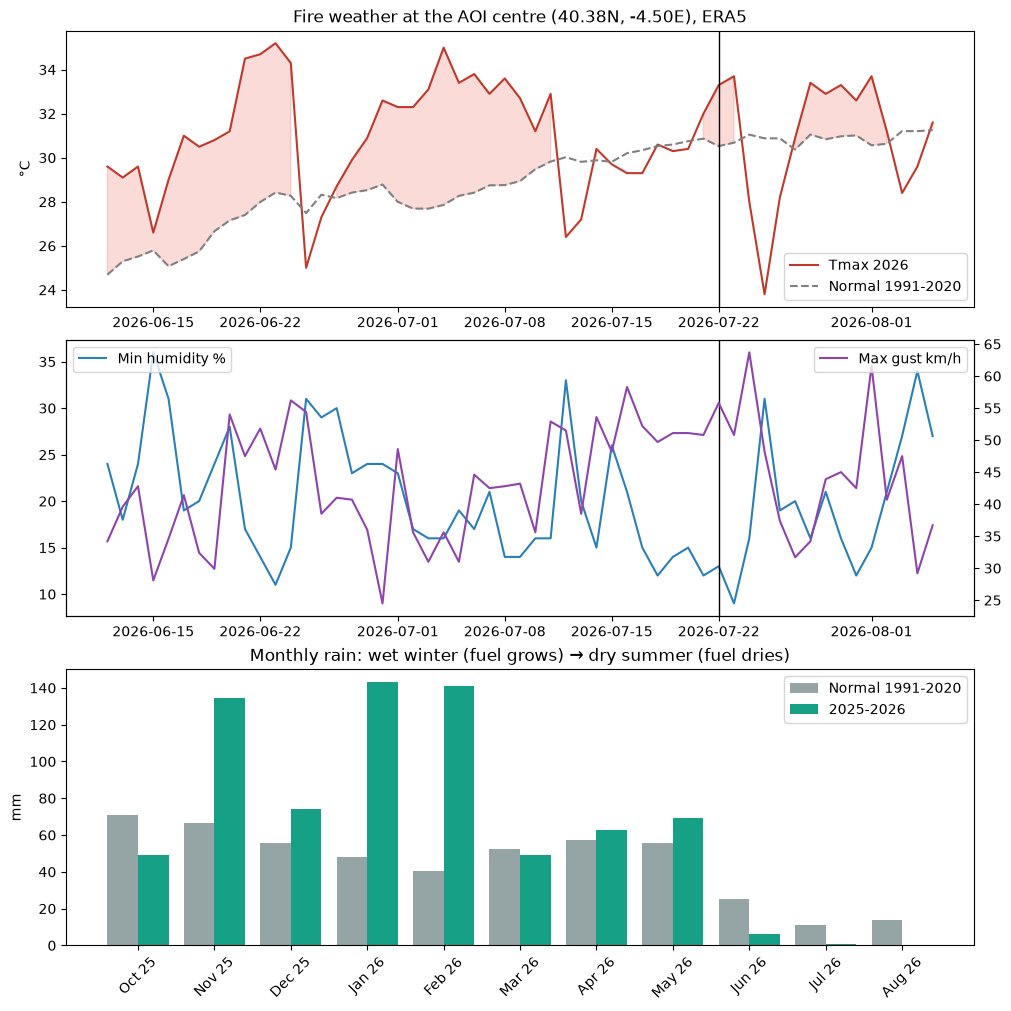

In [5]:
win = obs.loc[fire - pd.Timedelta(days=40): fire + pd.Timedelta(days=14)]
fig, ax = plt.subplots(3, 1, figsize=(10, 10), constrained_layout=True)
ax[0].plot(win.index, win["temperature_2m_max"], c="#c0392b", label="Tmax 2026")
ax[0].plot(win.index, win["tmax_normal"], c="grey", ls="--", label="Normal 1991-2020")
ax[0].fill_between(win.index, win["tmax_normal"], win["temperature_2m_max"],
                   where=win["temperature_2m_max"] > win["tmax_normal"], color="#e74c3c", alpha=.2)
ax[0].set_ylabel("°C"); ax[0].legend()
ax[1].plot(win.index, win["relative_humidity_2m_min"], c="#2980b9", label="Min humidity %")
a2 = ax[1].twinx()
a2.plot(win.index, win["wind_gusts_10m_max"], c="#8e44ad", label="Max gust km/h")
ax[1].legend(loc="upper left"); a2.legend(loc="upper right")
for a in ax[:2]:
    a.axvline(fire, c="k", lw=1)
x = np.arange(len(rain))
ax[2].bar(x - .2, rain["normal_mm"], .4, color="#95a5a6", label="Normal 1991-2020")
ax[2].bar(x + .2, rain["obs_mm"], .4, color="#16a085", label="2025-2026")
ax[2].set_xticks(x, [d.strftime("%b %y") for d in rain.index], rotation=45)
ax[2].set_ylabel("mm"); ax[2].legend()
ax[0].set_title(f"Fire weather at the AOI centre ({lat:.2f}N, {lon:.2f}E), ERA5")
ax[2].set_title("Monthly rain: wet winter (fuel grows) → dry summer (fuel dries)")
fig.savefig(OUT / "step6_fire_weather.png", dpi=140)
plt.show()

## What you learned
- An **API** gives you data straight into Python. No manual downloads.
- **Anomalies** (difference from the climate normal) say more than raw values: 38 °C means different things in January and in July.
- Fire risk builds up over months (fuel) and is triggered over days (heat, dry air, wind).

Next: notebook 07 checks our footprint against the official EFFIS perimeters.